# Charts for Task 1
We draw charts of the train data.
We save each chart as a picture in the report folder.

## 1. Load the data

In [1]:
import os
os.makedirs('../report', exist_ok=True)
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
train = pd.read_csv('../data/train_prep_v2.csv')
ham = train[train['label'] == 'ham']
spam = train[train['label'] == 'spam']
HAM = '#2a78d6'
SPAM = '#eb6834'
print(train.shape, len(ham), len(spam))

(4102, 9) 3601 501


## 2. Number of ham and spam

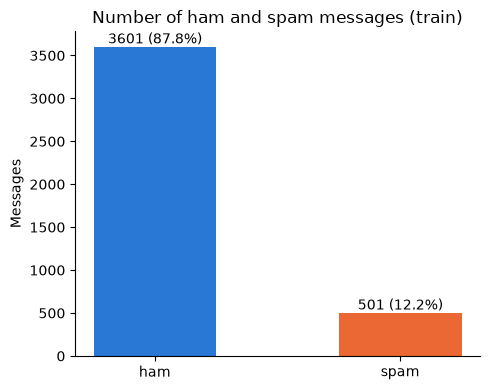

In [2]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['ham', 'spam'], [len(ham), len(spam)], color=[HAM, SPAM], width=0.5)
for i, n in enumerate([len(ham), len(spam)]):
    ax.text(i, n + 40, f'{n} ({100 * n / len(train):.1f}%)', ha='center')
ax.set_title('Number of ham and spam messages (train)')
ax.set_ylabel('Messages')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('../report/chart1_ham_spam.png', dpi=150)
plt.show()

## 3. Length of messages
For each class, we show the percent of messages in each length group (10 characters each).
We use percent, because there are many more ham messages than spam messages.

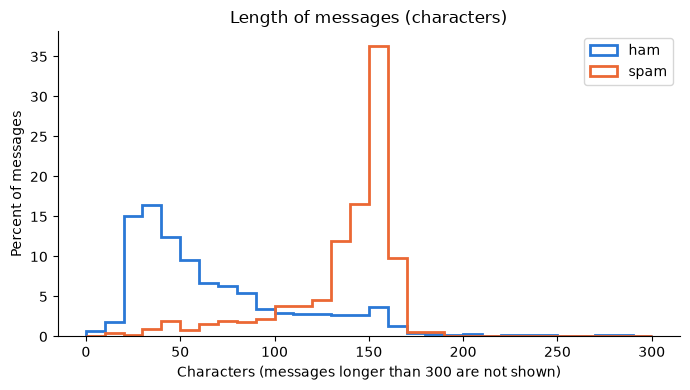

Messages longer than 300: 28


In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = range(0, 301, 10)
ax.hist(ham['length'], bins=bins, weights=[100 / len(ham)] * len(ham),
        histtype='step', linewidth=2, color=HAM, label='ham')
ax.hist(spam['length'], bins=bins, weights=[100 / len(spam)] * len(spam),
        histtype='step', linewidth=2, color=SPAM, label='spam')
ax.set_title('Length of messages (characters)')
ax.set_xlabel('Characters (messages longer than 300 are not shown)')
ax.set_ylabel('Percent of messages')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('../report/chart2_length.png', dpi=150)
plt.show()
print('Messages longer than 300:', (train['length'] > 300).sum())

## 4. Things that are different in ham and spam
For each thing, we show the percent of ham messages and spam messages that have it.

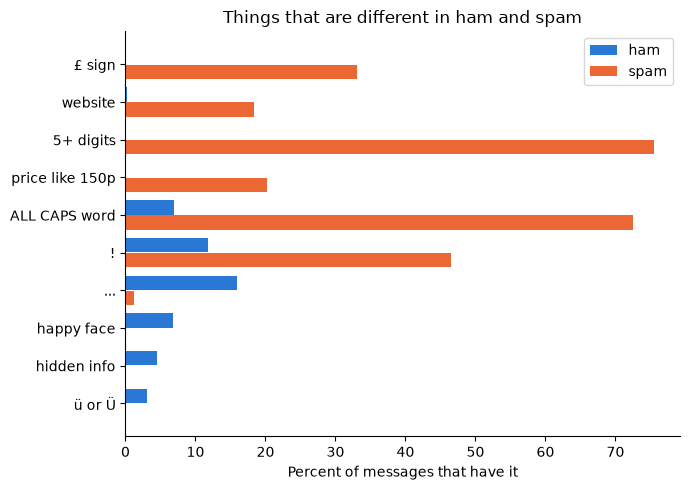

In [4]:
checks = [('£ sign', '£'),
          ('website', r'(?i)www\.|http|\w\.(?:com|co\.uk|net|org|biz|tv|ac|info)\b'),
          ('5+ digits', r'\d{5,}'), ('price like 150p', r'(?i)\b\d+(?:\.\d+)?p\b'),
          ('ALL CAPS word', r'\b[A-Z]{2,}\b'), ('!', '!'), ('...', r'\.\.\.'),
          ('happy face', r'[:;]-?[)DPp]'), ('hidden info', '&lt;'), ('ü or Ü', '[üÜ]')]
names, ham_pct, spam_pct = [], [], []
for name, pattern in checks:
    has = train['text'].str.contains(pattern)
    names.append(name)
    ham_pct.append(100 * has[train['label'] == 'ham'].mean())
    spam_pct.append(100 * has[train['label'] == 'spam'].mean())

fig, ax = plt.subplots(figsize=(7, 5))
y = range(len(names))
ax.barh([i - 0.2 for i in y], ham_pct, height=0.38, color=HAM, label='ham')
ax.barh([i + 0.2 for i in y], spam_pct, height=0.38, color=SPAM, label='spam')
ax.set_yticks(list(y))
ax.set_yticklabels(names)
ax.invert_yaxis()
ax.set_xlabel('Percent of messages that have it')
ax.set_title('Things that are different in ham and spam')
ax.legend()
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('../report/chart3_features.png', dpi=150)
plt.show()

## 5. Top 10 words
We count the words in the text after removing our stopwords (stop_text).

ham [('i', 1789), ('to', 1209), ('a', 783), ('u', 726), ('me', 583), ('my', 525), ('it', 438), ('for', 388), ('that', 383), ('im', 365)]
spam [('longnumber', 492), ('to', 448), ('a', 240), ('call', 235), ('pounds', 216), ('your', 180), ('for', 143), ('free', 142), ('2', 139), ('pence', 138)]


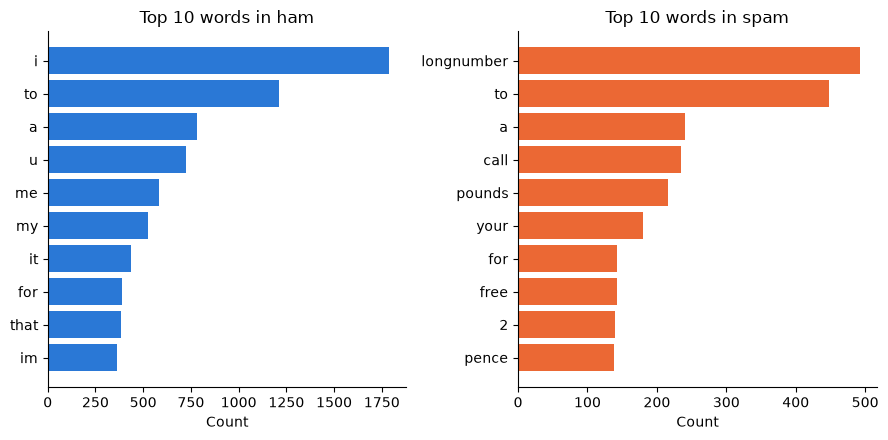

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for ax, df, color, title in [(axes[0], ham, HAM, 'ham'), (axes[1], spam, SPAM, 'spam')]:
    words = Counter(' '.join(df['stop_text']).split()).most_common(10)
    print(title, words)
    ax.barh([w for w, n in words], [n for w, n in words], color=color)
    ax.invert_yaxis()
    ax.set_title('Top 10 words in ' + title)
    ax.set_xlabel('Count')
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('../report/chart4_top_words.png', dpi=150)
plt.show()